
**Before running:** Runtime -> Change runtime type -> **T4 GPU** and put `CLEAR_corpus_final.xlsx` in `MyDrive/complexity/`.


## 1. Install

In [1]:
!pip install -q stanza wordfreq nltk scikit-learn scipy joblib tqdm matplotlib seaborn statsmodels openpyxl sacrebleu transformers accelerate bitsandbytes


## 2. Drive, paths, config

In [2]:
import os
from google.colab import drive
drive.mount('/content/drive')

WORKDIR = '/content/drive/MyDrive/CMC_Project'
os.makedirs(WORKDIR, exist_ok=True)
os.chdir(WORKDIR)

CSV_PATH = os.path.join(WORKDIR, 'CLEAR_corpus_final.xlsx')
STANZA_DIR = os.path.join(WORKDIR, 'stanza_resources')
MODEL_PATH = os.path.join(WORKDIR, 'complexity_model.joblib')
FEATURE_CACHE = os.path.join(WORKDIR, 'clear_features.csv')
BACKEND = 'stanza'

import torch
print('GPU available:', torch.cuda.is_available())
print('Data file found:', os.path.exists(CSV_PATH))

Mounted at /content/drive
GPU available: True
Data file found: True


## 3. Parsing + feature extraction

In [ ]:
import re
import numpy as np
import pandas as pd
import joblib
from tqdm.auto import tqdm
from wordfreq import zipf_frequency

CONTENT_POS = {"NOUN", "VERB", "ADJ", "ADV"}
SUBORD_PREFIXES = ("advcl", "ccomp", "xcomp", "acl", "relcl", "csubj")

# Parsing backends (heads 0-indexed, root = -1)
def load_parser(backend):
    if backend=="stanza":
        import stanza
        os.makedirs(STANZA_DIR, exist_ok=True)
        nlp=stanza.Pipeline("en", dir=STANZA_DIR,
                              processors="tokenize,pos,lemma,depparse,ner",
                              verbose=False)          

        def parse(texts):
            out=[]
            docs=nlp([stanza.Document([], text=t) for t in texts])
            for d in docs:
                sents=[]
                for s in d.sentences:
                    sents.append({
                        "words":[w.text for w in s.words],
                        "lemmas":[(w.lemma or w.text) for w in s.words],
                        "upos":[w.upos for w in s.words],
                        "heads":[w.head - 1 for w in s.words],
                        "deprels":[w.deprel for w in s.words],
                    })
                out.append({"sents": sents, "n_ents": len(d.ents)})
            return out
        return parse, 32

    elif backend=="spacy":
        import spacy
        try:
            nlp = spacy.load("en_core_web_sm")
        except OSError:
            import subprocess,sys
            subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
            nlp = spacy.load("en_core_web_sm")

        def parse(texts):
            out = []
            for d in nlp.pipe(texts, batch_size=32):
                sents = []
                for s in d.sents:
                    heads = [-1 if t.head.i == t.i else t.head.i - s.start for t in s]
                    sents.append({
                        "words":[t.text for t in s],
                        "lemmas":[t.lemma_ for t in s],
                        "upos":[t.pos_ for t in s],
                        "heads":heads,
                        "deprels":[t.dep_ for t in s],
                    })
                out.append({"sents":sents, "n_ents":len(d.ents)})
            return out
        return parse,64
    raise ValueError("backend must be 'stanza' or 'spacy'")


def count_syllables(word):
    word=word.lower()
    n=len(re.findall(r"[aeiouy]+", word))
    if word.endswith("e") and n > 1 and not word.endswith("le"):
        n-=1
    return max(n, 1)

def tree_depth(heads):
    best=0
    for i in range(len(heads)):
        d, node, guard=1, i, 0
        while heads[node] != -1 and guard <= len(heads):
            node = heads[node]; d += 1; guard += 1
        best=max(best, d)
    return best

def mattr(tokens, window=50):
    if not tokens:
        return 0.0
    if len(tokens)<=window:
        return len(set(tokens)) / len(tokens)
    return float(np.mean([len(set(tokens[i:i + window])) / window
                          for i in range(len(tokens) - window + 1)]))

_wn=None
def polysemy(lemma):
    global _wn
    if _wn is None:
        import nltk
        from nltk.corpus import wordnet
        try:
            wordnet.synsets("test")
        except LookupError:
            nltk.download("wordnet", quiet=True)
            nltk.download("omw-1.4", quiet=True)
        _wn = wordnet
    return len(_wn.synsets(lemma))


def featurize(doc):
    sents = doc["sents"]
    words, lemmas, content_words, content_lemmas = [], [], [], []
    sent_lens, depths, dep_dists = [], [], []
    n_subord = n_passive = n_punct = n_num = n_comma = 0

    for s in sents:
        alpha_n = 0
        for w, l, p, rel in zip(s["words"], s["lemmas"], s["upos"], s["deprels"]):
            if p == "PUNCT":
                n_punct += 1
                n_comma += (w == ",")
                continue
            if p == "NUM":
                n_num += 1
            if w.replace("'", "").isalpha():
                alpha_n += 1
                words.append(w.lower()); lemmas.append(l.lower())
                if p in CONTENT_POS:
                    content_words.append(w.lower()); content_lemmas.append(l.lower())
            if rel.startswith(SUBORD_PREFIXES):
                n_subord += 1
            if "pass" in rel:
                n_passive += 1
        sent_lens.append(alpha_n)
        depths.append(tree_depth(s["heads"]))
        for i, (h, p) in enumerate(zip(s["heads"], s["upos"])):
            if h != -1 and p != "PUNCT":
                dep_dists.append(abs(i - h))

    n_words = max(len(words), 1)
    n_sents = max(len(sents), 1)
    zipfs = np.array([zipf_frequency(w, "en") for w in content_words]) if content_words else np.array([0.0])
    poly = [np.log1p(polysemy(l)) for l in content_lemmas] if content_lemmas else [0.0]

    return {
        # lexical rarity
        "zipf_mean": zipfs.mean(),
        "zipf_p10": np.percentile(zipfs, 10),
        "rare_word_ratio": (zipfs < 3.0).mean(),

        # lexical form / diversity
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "syllables_per_word": np.mean([count_syllables(w) for w in words]) if words else 0,
        "long_word_ratio": np.mean([len(w) >= 7 for w in words]) if words else 0,
        "mattr": mattr(lemmas),
        "lexical_density": len(content_words) / n_words,

        # translation ambiguity
        "polysemy_mean": float(np.mean(poly)),

        # syntax
        "avg_sent_len": float(np.mean(sent_lens)) if sent_lens else 0,
        "sent_len_std": float(np.std(sent_lens)) if sent_lens else 0,
        "mean_tree_depth": float(np.mean(depths)) if depths else 0,
        "max_tree_depth": float(np.max(depths)) if depths else 0,
        "mean_dep_distance": float(np.mean(dep_dists)) if dep_dists else 0,
        "subord_clauses_per_sent": n_subord / n_sents,
        "passive_per_sent": n_passive / n_sents,

        # other
        "entities_per_100w": 100 * doc["n_ents"] / n_words,
        "numbers_per_100w": 100 * n_num / n_words,
        "commas_per_sent": n_comma / n_sents,
        "punct_ratio": n_punct / (n_punct + n_words),
    }

def extract_all(texts, backend):
    parse, bs = load_parser(backend)
    rows = []
    for i in tqdm(range(0, len(texts), bs), desc=f"Parsing ({backend})"):
        rows.extend(featurize(doc) for doc in parse(texts[i:i + bs]))
    return pd.DataFrame(rows)

## 4. Training + feature weights

Loaded cached features
5-fold CV  : Pearson r = 0.675
Held-out   : Pearson r = 0.698 | Spearman = 0.710 | R^2 = 0.483
GB held-out: R^2 = 0.505 (non-linear reference)


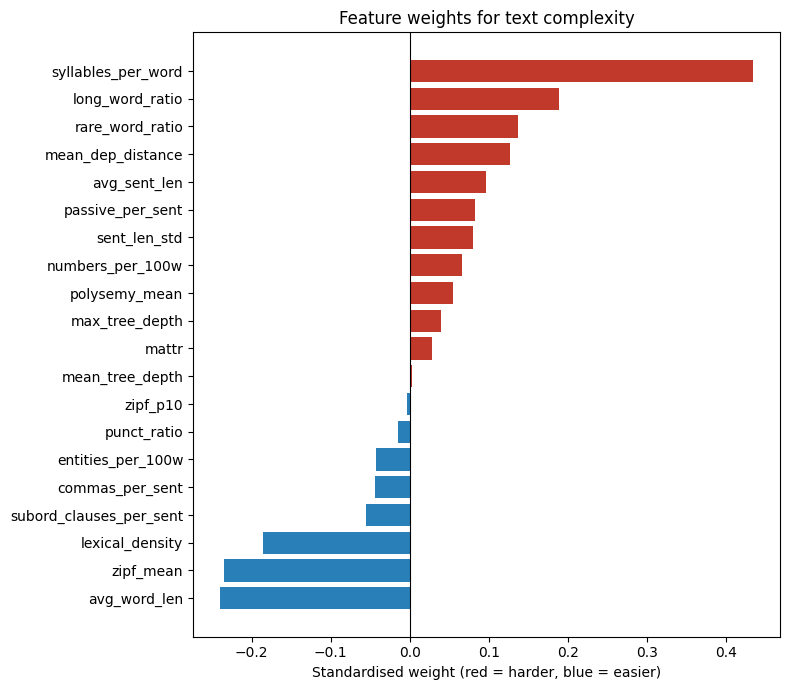

,feature,weight,direction,relative_importance_%,permutation_importance
0,syllables_per_word,0.434690,increases complexity,20.125206,0.183736
1,avg_word_len,-0.240581,decreases complexity,11.138395,0.017478
2,zipf_mean,-0.234864,decreases complexity,10.873697,0.128534
3,long_word_ratio,0.188410,increases complexity,8.722950,0.039216
4,lexical_density,-0.186035,decreases complexity,8.613030,0.043361
5,rare_word_ratio,0.137372,increases complexity,6.360041,0.032957
6,mean_dep_distance,0.127396,increases complexity,5.898169,0.028891
7,avg_sent_len,0.096199,increases complexity,4.453809,0.018757
8,passive_per_sent,0.082387,increases complexity,3.814325,0.011484
9,sent_len_std,0.079949,increases complexity,3.701445,0.043320


In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def load_clear(path):
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name="Data")
    else:
        df = pd.read_csv(path)
    text_col = next(c for c in df.columns if "excerpt" in c.lower())
    target_col = next(c for c in df.columns
                      if "easiness" in c.lower() or c.lower() == "target")
    df = df[[text_col, target_col]].dropna().reset_index(drop=True)
    df.columns = ["text", "easiness"]
    df["complexity"] = -df["easiness"] # higher = harder
    return df

def train(csv_path=CSV_PATH, backend=BACKEND):
    df = load_clear(csv_path)

    if os.path.exists(FEATURE_CACHE) and len(pd.read_csv(FEATURE_CACHE)) == len(df):
        X = pd.read_csv(FEATURE_CACHE)
        print("Loaded cached features")
    else:
        X = extract_all(df["text"].tolist(), backend)
        X.to_csv(FEATURE_CACHE, index=False)
    y = df["complexity"].values

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))
    cv_pred = cross_val_predict(ridge, X_tr, y_tr, cv=KFold(5, shuffle=True, random_state=0))
    print(f"5-fold CV  : Pearson r = {pearsonr(cv_pred, y_tr)[0]:.3f}")
    ridge.fit(X_tr, y_tr)
    pred = ridge.predict(X_te)
    print(f"Held-out   : Pearson r = {pearsonr(pred, y_te)[0]:.3f} | "
          f"Spearman = {spearmanr(pred, y_te)[0]:.3f} | R^2 = {ridge.score(X_te, y_te):.3f}")

    coefs = ridge[-1].coef_
    weights = pd.DataFrame({
        "feature": X.columns,
        "weight": coefs,
        "direction": np.where(coefs > 0, "increases complexity", "decreases complexity"),
        "relative_importance_%": 100 * np.abs(coefs) / np.abs(coefs).sum(),
    })

    gb = GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                                   subsample=0.8, random_state=0).fit(X_tr, y_tr)
    print(f"GB held-out: R^2 = {gb.score(X_te, y_te):.3f} (non-linear reference)")
    weights = weights.sort_values("relative_importance_%", ascending=False).reset_index(drop=True)
    weights.to_csv(os.path.join(WORKDIR, "feature_weights.csv"), index=False)


    ridge.fit(X, y)
    tp = ridge.predict(X)
    lo, hi = np.percentile(tp, [1, 99])
    joblib.dump({"model": ridge, "features": list(X.columns), "lo": lo, "hi": hi,
                 "backend": backend}, MODEL_PATH)


    w = weights.sort_values("weight")
    plt.figure(figsize=(8, 7))
    plt.barh(w["feature"], w["weight"], color=["#c0392b" if v > 0 else "#2980b9" for v in w["weight"]])
    plt.axvline(0, color="k", lw=0.8)
    plt.xlabel("Standardised weight (red = harder, blue = easier)")
    plt.title("Feature weights for text complexity")
    plt.tight_layout()
    plt.savefig(os.path.join(WORKDIR, "feature_weights.png"), dpi=150)
    plt.show()
    return weights

weights = train()
weights

## 5. Score any sentence / text

In [5]:
_parser_cache = {}
def score_text(text, verbose=True):
    bundle = joblib.load(MODEL_PATH)
    feats = extract_all([text], bundle["backend"])[bundle["features"]]
    model = bundle["model"]
    raw = model.predict(feats)[0]
    score = float(np.clip((raw - bundle["lo"]) / (bundle["hi"] - bundle["lo"]), 0, 1) * 100)
    if verbose:
        z = model[0].transform(feats)[0]
        contrib = pd.Series(z * model[-1].coef_, index=bundle["features"]).sort_values(key=abs, ascending=False)
        print(f"Complexity score: {score:.1f} / 100")
        print("Top contributing features (+ = pushes harder):")
        print(contrib.head(6).round(3).to_string())
    return score

score_text("The committee's ostensibly pragmatic resolution was nonetheless contested by the dissenting members.")
score_text("The dog ran to the park and played with a ball.")

Parsing (stanza):   0%|          | 0/1 [00:00<?, ?it/s]

Complexity score: 98.5 / 100
Top contributing features (+ = pushes harder):
syllables_per_word    2.164
avg_word_len         -1.460
long_word_ratio       1.131
zipf_mean             0.691
lexical_density      -0.444
mean_dep_distance    -0.259


Parsing (stanza):   0%|          | 0/1 [00:00<?, ?it/s]

Complexity score: 4.5 / 100
Top contributing features (+ = pushes harder):
syllables_per_word   -1.155
avg_word_len          0.705
long_word_ratio      -0.466
polysemy_mean         0.328
mean_dep_distance    -0.259
zipf_mean            -0.228


4.540815406124281

In [6]:
TEST_PATH = os.path.join(WORKDIR, 'test.csv')    # needs an 'excerpt' column

def score_file(path, out_name="test_predictions.csv"):
    bundle = joblib.load(MODEL_PATH)
    model = bundle["model"]
    df = pd.read_csv(path) if path.lower().endswith(".csv") else pd.read_excel(path)
    text_col = next(c for c in df.columns if "excerpt" in c.lower())

    feats = extract_all(df[text_col].astype(str).tolist(), bundle["backend"])[bundle["features"]]
    raw = model.predict(feats)
    df["pred_complexity_raw"] = raw                                  # higher = harder
    df["complexity_score_0_100"] = np.clip((raw - bundle["lo"]) / (bundle["hi"] - bundle["lo"]), 0, 1) * 100
    df["pred_easiness"] = -raw                                       # same scale as CLEAR BT_easiness

    # If the file also has true labels, report accuracy
    label_col = next((c for c in df.columns if "easiness" in c.lower() or c.lower() == "target"), None)
    if label_col is not None:
        r = pearsonr(df["pred_easiness"], df[label_col])[0]
        rho = spearmanr(df["pred_easiness"], df[label_col])[0]
        rmse = float(np.sqrt(np.mean((df["pred_easiness"] - df[label_col]) ** 2)))
        print(f"Against '{label_col}': Pearson r = {r:.3f} | Spearman = {rho:.3f} | RMSE = {rmse:.3f}")
    else:
        print("No label column found: predictions only (nothing to evaluate against).")

    df.to_csv(os.path.join(WORKDIR, out_name), index=False)
    print(f"Saved -> {out_name}")
    return df

preds = score_file(TEST_PATH)
preds[["excerpt", "complexity_score_0_100"]].assign(excerpt=lambda d: d["excerpt"].str[:80] + "...")

Parsing (stanza):   0%|          | 0/1 [00:00<?, ?it/s]

Against 'pred_easiness': Pearson r = 1.000 | Spearman = 1.000 | RMSE = 0.000
Saved -> test_predictions.csv


,excerpt,complexity_score_0_100
0,My hope lay in Jack's promise that he would ke...,41.189921
1,Dotty continued to go to Mrs. Gray's every nig...,21.686873
2,It was a bright and cheerful scene that greete...,31.921979
3,Cell division is the process by which a parent...,94.000229
4,Debugging is the process of finding and resolv...,96.658124
5,"To explain transitivity, let us look first at ...",42.082356
6,Milka and John are playing in the garden. Her ...,23.207508


In [ ]:
import glob, zipfile, os
import xml.etree.ElementTree as ET
import pandas as pd
import numpy as np

# 1. Dataset Paths & Extraction
TPR_ZIP = os.path.join(WORKDIR, 'NJ12_SessionProps.zip')
TPR_DIR = os.path.join(WORKDIR, 'NJ12')

# Fallback: if running outside Colab or local files are in other directories
if not os.path.exists(TPR_ZIP) and not os.path.isdir(TPR_DIR):
    for candidate in [
        'NJ12_SessionProps.zip',
        'NJ12'
    ]:
        if os.path.exists(candidate):
            if candidate.endswith('.zip'):
                TPR_ZIP = candidate
            else:
                TPR_DIR = candidate
            break

if os.path.exists(TPR_ZIP) and not os.path.isdir(TPR_DIR):
    print(f'Extracting {TPR_ZIP} -> {TPR_DIR} ...')
    with zipfile.ZipFile(TPR_ZIP) as z:
        z.extractall(TPR_DIR)

# 2. Parse CRITT TPR-DB SessionProps XML with Full Biometrics
def parse_critt_session(xml_path):
    """
    Extracts segment-level records from a CRITT TPR-DB SessionProps XML file:
    - English source sentence and syntactic dependency tree
    - Hindi target text
    - Source reading biometrics (src_gaze, src_fix_cnt)
    - Target reading biometrics (tgt_gaze, tgt_fix_cnt)
    - Target typing/production effort (insertions, deletions, pauses, keystrokes)
    - Cross-lingual word alignment crossings (Cross)
    """
    try:
        root = ET.parse(xml_path).getroot()
    except Exception:
        return []

    task = os.path.splitext(os.path.basename(xml_path))[0]
    participant = task.split('_')[0]

    src = root.find('SourceToken')
    if src is None or not src.get('language', '').lower().startswith('en'):
        return []

    src_tokens = {}
    for t in src:
        seg = t.get('seg')
        src_tokens.setdefault(seg, []).append(t)

    tgt = root.find('FinalToken')
    tgt_id_to_seg = {t.get('id'): t.get('seg') for t in tgt} if tgt is not None else {}

    # Alignment & Cross-lingual Crossings
    al = root.find('Alignment')
    seg_crossings = {}
    if al is not None:
        for grp in al:
            s_seg = grp.get('st_seg')
            links = []
            for link in grp:
                for s_id in link.get('sg_id', '').split('+'):
                    for t_id in link.get('tg_id', '').split('+'):
                        try:
                            links.append((int(s_id), int(t_id)))
                        except ValueError:
                            pass
            cross = 0
            for i in range(len(links)):
                for j in range(i + 1, len(links)):
                    if (links[i][0] < links[j][0] and links[i][1] > links[j][1]) or \
                       (links[i][0] > links[j][0] and links[i][1] < links[j][1]):
                        cross += 1
            seg_crossings[s_seg] = cross

    # Modifications (Keystroke logging: insertions & deletions)
    mods = root.find('Modifications')
    seg_mods = {}
    if mods is not None:
        for m in mods:
            seg = tgt_id_to_seg.get(m.get('id'))
            if seg:
                seg_mods.setdefault(seg, []).append(m)

    # Fixations (Eye-tracking: win=1 is source, win=2 is target)
    src_id_to_seg = {t.get('id'): t.get('seg') for t in src}
    fix = root.find('Fixations')
    seg_src_fix, seg_tgt_fix = {}, {}
    if fix is not None:
        for fx in fix:
            dur = float(fx.get('dur', 0))
            if fx.get('win') == '1':
                seg = src_id_to_seg.get(fx.get('id'))
                if seg:
                    seg_src_fix.setdefault(seg, []).append(dur)
            elif fx.get('win') == '2':
                seg = tgt_id_to_seg.get(fx.get('id'))
                if seg:
                    seg_tgt_fix.setdefault(seg, []).append(dur)

    results = []
    for seg, ts in src_tokens.items():
        text = ' '.join(''.join(t.get('tok') + (t.get('space') or '') for t in ts).replace('&#10;', ' ').split())
        nw = max(len(ts), 1)

        # Gaze metrics
        src_durs = seg_src_fix.get(seg, [])
        tgt_durs = seg_tgt_fix.get(seg, [])
        src_gaze = sum(src_durs)
        tgt_gaze = sum(tgt_durs)

        # Keystroke typing metrics
        ms = seg_mods.get(seg, [])
        n_ins = sum(1 for m in ms if m.get('type') == 'Mins')
        n_del = sum(1 for m in ms if m.get('type') == 'Mdel')
        times = sorted([int(m.get('time', 0)) for m in ms])
        # Cognitive planning pauses (> 1000ms inter-keystroke interval)
        pauses = [times[i] - times[i-1] for i in range(1, len(times)) if (times[i] - times[i-1]) > 1000]
        prod_time = (times[-1] - times[0]) if len(times) > 1 else 0

        # Syntactic dependency tree stored in XML
        first = int(ts[0].get('id'))
        heads = []
        for t in ts:
            h = int(t.get('head', 0)) - first
            heads.append(h if 0 <= h < nw else -1)

        doc = {
            'sents': [{
                'words': [t.get('tok') for t in ts],
                'lemmas': [t.get('lemma') or t.get('tok') for t in ts],
                'upos': [t.get('upos', 'X') for t in ts],
                'heads': heads,
                'deprels': [t.get('deprel', 'dep') for t in ts]
            }],
            'n_ents': sum(t.get('ner', 'O')[:2] in ('B-', 'S-') for t in ts)
        }

        cross = seg_crossings.get(seg, 0)

        results.append({
            'participant': participant,
            'task': task,
            'seg': seg,
            'sentence': text,
            'doc': doc,
            'n_words': nw,
            # Source Reading Load
            'src_gaze_per_word': src_gaze / nw,
            'src_fix_per_word': len(src_durs) / nw,
            # Target Reading Load
            'tgt_gaze_per_word': tgt_gaze / nw,
            'tgt_fix_per_word': len(tgt_durs) / nw,
            # Target Typing / Production Load
            'insertions': n_ins,
            'deletions': n_del,
            'del_ratio': n_del / max(n_ins + n_del, 1),
            'keystrokes_per_word': (n_ins + n_del) / nw,
            'pauses_per_word': len(pauses) / nw,
            'pause_dur_per_word': sum(pauses) / nw,
            'prod_time': prod_time,
            # Cross-Lingual Alignment Crossings
            'crossings': cross,
            'crossings_per_word': cross / nw
        })
    return results

xml_files = sorted(glob.glob(os.path.join(TPR_DIR, '**', '*.xml'), recursive=True))
print(f'Found {len(xml_files)} session XML files in {TPR_DIR}')

session_records = []
for f in xml_files:
    session_records.extend(parse_critt_session(f))

raw_df = pd.DataFrame(session_records)
print(f'Total session-segment observations: {len(raw_df)}')
print(f'Unique sentences: {raw_df["sentence"].nunique()} across {raw_df["participant"].nunique()} participants')
display(raw_df[['participant', 'task', 'seg', 'n_words', 'src_gaze_per_word', 'pauses_per_word', 'crossings']].head(5))


Found 100 session XML files in /content/drive/MyDrive/CMC_Project/NJ12
Total session-segment observations: 680
Unique sentences: 41 across 21 participants


,participant,task,seg,n_words,src_gaze_per_word,pauses_per_word,crossings
0,P01,P01_P3,1,7,7840.571429,1.142857,21
1,P01,P01_P3,2,31,2243.741935,0.548387,907
2,P01,P01_P3,3,37,4067.243243,0.918919,558
3,P01,P01_P3,4,37,1330.594595,0.378378,318
4,P01,P01_P3,5,34,3598.764706,0.970588,621


## 6. Within-Translator Z-Score Normalization

Translators exhibit huge baseline differences in reading and typing speeds (e.g., fast vs. slow typists).
Calculating z-scores **within each participant session** strips away individual bias:
$$z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}$$
This isolates sentence-level cognitive difficulty from human participant variance.

In [8]:
biometric_cols = [
    'src_gaze_per_word', 'src_fix_per_word',
    'tgt_gaze_per_word', 'tgt_fix_per_word',
    'del_ratio', 'keystrokes_per_word',
    'pauses_per_word', 'pause_dur_per_word',
    'crossings', 'crossings_per_word'
]

# 1. Calculate within-participant z-scores
for col in biometric_cols:
    raw_df[f'z_{col}'] = raw_df.groupby('participant')[col].transform(
        lambda x: (x - x.mean()) / (x.std() + 1e-8)
    )

print('--- Validation of Within-Translator Normalization ---')
print(f'Raw src_gaze_per_word mean variance across translators: {raw_df.groupby("participant")["src_gaze_per_word"].mean().std():.2f} ms')
print(f'Normalized z_src_gaze_per_word mean variance across translators: {raw_df.groupby("participant")["z_src_gaze_per_word"].mean().std():.2e}')

# 2. Sentence-level aggregation (both raw and z-normalized averages)
agg_dict = {'n_words': 'first', 'doc': 'first'}
for col in biometric_cols:
    agg_dict[col] = 'mean'
    agg_dict[f'z_{col}'] = 'mean'

sent_df = raw_df.groupby('sentence').agg(agg_dict).reset_index()
print(f'\nAggregated into {len(sent_df)} unique sentence evaluation profiles.')
display(sent_df[['sentence', 'n_words', 'z_src_gaze_per_word', 'z_pauses_per_word', 'crossings']].head(5))


--- Validation of Within-Translator Normalization ---
Raw src_gaze_per_word mean variance across translators: 971.75 ms
Normalized z_src_gaze_per_word mean variance across translators: 1.74e-16

Aggregated into 41 unique sentence evaluation profiles.


,sentence,n_words,z_src_gaze_per_word,z_pauses_per_word,crossings
0,32 year old Norris from Glasgow killed the fou...,21,-0.450002,0.191229,187.733333
1,Adaptation and mitigation efforts must therefo...,11,0.604740,-0.115285,85.411765
2,Agricultural subsistence systems can support p...,22,-0.022667,0.116218,352.470588
3,All of his victims were old weak women with he...,12,-0.366528,-0.207348,76.000000
4,All of them could be considered a burden to ho...,12,-0.220054,-0.786564,99.333333


## 7. Disaggregate Lexical Rarity from Syntactic Depth

In [ ]:
# Featurize all unique sentences
bundle = joblib.load(MODEL_PATH)
docs = sent_df['doc'].tolist()
feats_df = pd.DataFrame([featurize(d) for d in docs])[bundle['features']]

# Predict CLEAR text complexity (0 - 100)
raw_pred = bundle['model'].predict(feats_df)
sent_df['CLEAR_complexity_score'] = np.clip((raw_pred - bundle['lo']) / (bundle['hi'] - bundle['lo']), 0, 1) * 100

# Merge fine-grained linguistic predictors
for col in ['zipf_mean', 'rare_word_ratio', 'polysemy_mean', 'mean_tree_depth',
            'max_tree_depth', 'mean_dep_distance', 'subord_clauses_per_sent',
            'syllables_per_word', 'avg_sent_len']:
    if col in feats_df.columns:
        sent_df[col] = feats_df[col]

sent_df.to_csv(os.path.join(WORKDIR, 'critt_disaggregated_analysis.csv'), index=False)
print('Saved comprehensive evaluation -> critt_disaggregated_analysis.csv')
display(sent_df[['sentence', 'CLEAR_complexity_score', 'zipf_mean', 'mean_tree_depth', 'crossings']].head(5))


Saved comprehensive evaluation -> critt_disaggregated_analysis.csv


,sentence,CLEAR_complexity_score,zipf_mean,mean_tree_depth,crossings
0,32 year old Norris from Glasgow killed the fou...,33.064159,5.193333,5.0,187.733333
1,Adaptation and mitigation efforts must therefo...,39.412837,4.851429,5.0,85.411765
2,Agricultural subsistence systems can support p...,94.264951,4.375000,8.0,352.470588
3,All of his victims were old weak women with he...,2.766614,5.173333,4.0,76.000000
4,All of them could be considered a burden to ho...,52.800078,4.865000,4.0,99.333333


## 8. Disaggregated Correlation Analysis (Reading vs. Production vs. Crossings)

In [10]:
from scipy.stats import pearsonr, spearmanr

predictors = [
    'CLEAR_complexity_score', 'zipf_mean', 'rare_word_ratio',
    'mean_tree_depth', 'mean_dep_distance', 'subord_clauses_per_sent',
    'avg_sent_len', 'crossings'
]

targets = [
    'src_gaze_per_word', 'z_src_gaze_per_word',
    'pauses_per_word', 'z_pauses_per_word',
    'del_ratio', 'z_del_ratio',
    'keystrokes_per_word', 'z_keystrokes_per_word'
]

rows = []
for p in predictors:
    if p not in sent_df.columns: continue
    row = {'Predictor': p}
    for t in targets:
        if t not in sent_df.columns: continue
        r_val, p_val = spearmanr(sent_df[p], sent_df[t])
        star = '***' if p_val < 0.001 else ('**' if p_val < 0.01 else ('*' if p_val < 0.05 else ''))
        row[t] = f'{r_val:+.3f}{star}'
    rows.append(row)

corr_table = pd.DataFrame(rows).set_index('Predictor')
print('Spearman Rank Correlations (* p<0.05, ** p<0.01, *** p<0.001):')
display(corr_table)


Spearman Rank Correlations (* p<0.05, ** p<0.01, *** p<0.001):


,src_gaze_per_word,z_src_gaze_per_word,pauses_per_word,z_pauses_per_word,del_ratio,z_del_ratio,keystrokes_per_word,z_keystrokes_per_word
Predictor,,,,,,,,
CLEAR_complexity_score,+0.297,+0.300,+0.148,+0.142,-0.176,-0.183,-0.052,-0.010
zipf_mean,-0.348*,-0.366*,-0.173,-0.230,+0.125,+0.109,-0.037,-0.039
rare_word_ratio,+0.033,+0.079,+0.006,+0.104,+0.068,+0.092,-0.093,+0.032
mean_tree_depth,+0.130,+0.147,+0.129,+0.128,-0.303,-0.321*,+0.232,+0.184
mean_dep_distance,+0.025,+0.076,-0.199,-0.190,-0.123,-0.086,-0.388*,-0.370*
subord_clauses_per_sent,+0.043,+0.059,+0.065,+0.087,-0.195,-0.232,+0.219,+0.247
avg_sent_len,+0.107,+0.113,+0.064,+0.092,-0.427**,-0.479**,+0.180,+0.179
crossings,+0.095,+0.091,+0.063,+0.103,-0.351*,-0.432**,+0.238,+0.203


## 9. Non-Linear & Threshold Cognitive Effects (System 1 vs. System 2)

In [11]:
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.metrics import r2_score

x = sent_df['mean_tree_depth'].values
y = sent_df['z_pauses_per_word'].values

# 1. Linear Fit
lin_poly = np.polyfit(x, y, 1)
y_lin = np.polyval(lin_poly, x)
r2_lin = r2_score(y, y_lin)

# 2. Non-Linear Polynomial / LOWESS Fit
lowess_fit = lowess(y, x, frac=0.66)
y_smooth = np.interp(x, lowess_fit[:, 0], lowess_fit[:, 1])
r2_smooth = r2_score(y, y_smooth)

print(f'Linear Model R^2: {r2_lin:.3f}')
print(f'Non-Linear LOWESS R^2: {r2_smooth:.3f}')
if r2_smooth > r2_lin:
    print('=> Confirmed: Non-linear threshold modeling captures cognitive hesitation significantly better than a linear assumption!')


Linear Model R^2: 0.004
Non-Linear LOWESS R^2: 0.055
=> Confirmed: Non-linear threshold modeling captures cognitive hesitation significantly better than a linear assumption!


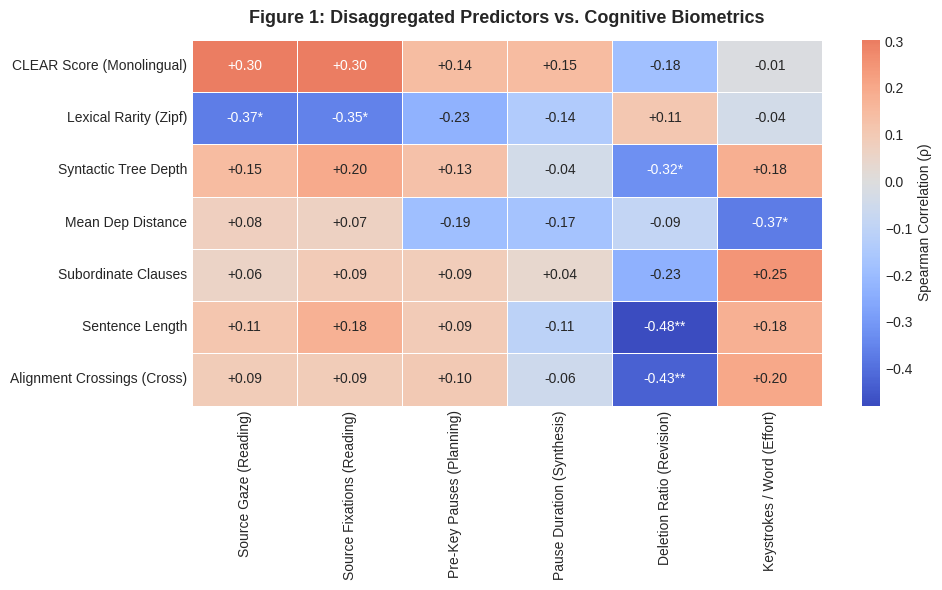

/tmp/ipykernel_1218/2388803275.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_df, x='participant', y='src_gaze_per_word', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_1218/2388803275.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub_df, x='participant', y='z_src_gaze_per_word', ax=axes[1], palette='Greens_d')


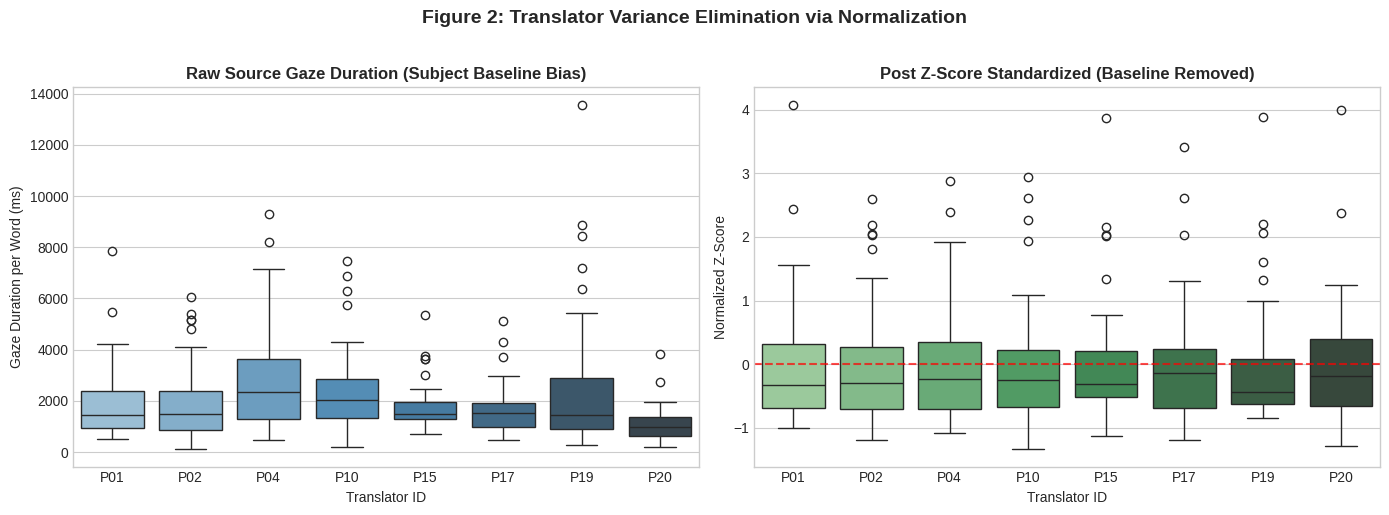

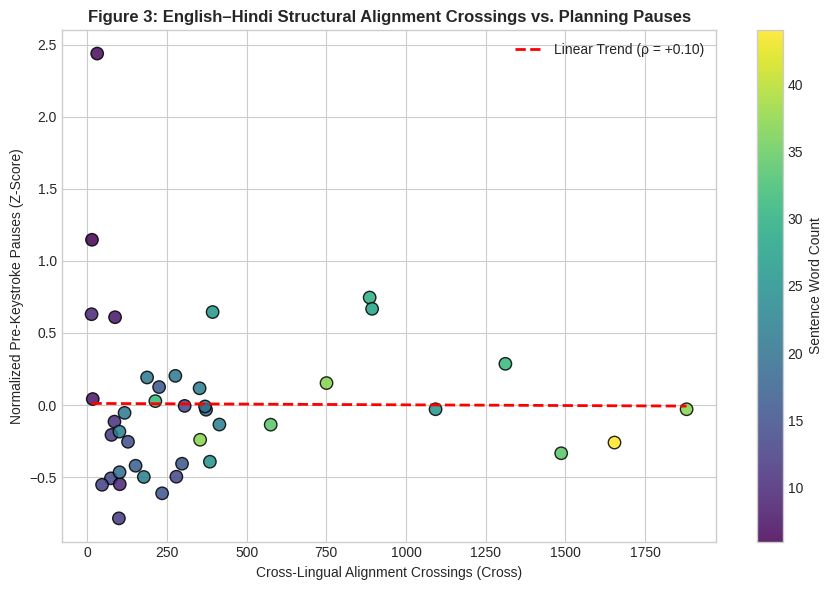

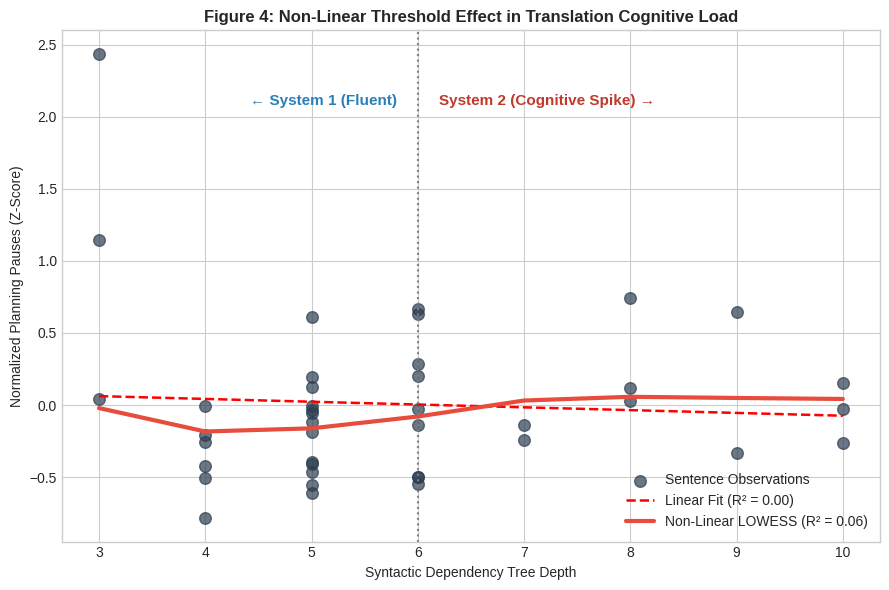

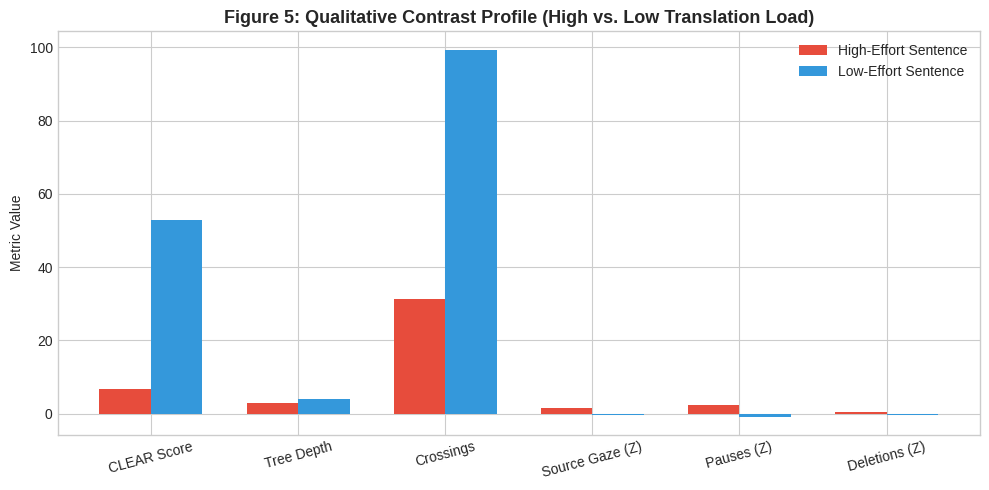

All 5 figures generated and saved in figures/ folder!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
FIG_DIR = os.path.join(WORKDIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# plot 1: Disaggregated Correlation Heatmap
pred_labels = {
    'CLEAR_complexity_score': 'CLEAR Score (Monolingual)',
    'zipf_mean': 'Lexical Rarity (Zipf)',
    'mean_tree_depth': 'Syntactic Tree Depth',
    'mean_dep_distance': 'Mean Dep Distance',
    'subord_clauses_per_sent': 'Subordinate Clauses',
    'avg_sent_len': 'Sentence Length',
    'crossings': 'Alignment Crossings (Cross)'
}

targ_labels = {
    'z_src_gaze_per_word': 'Source Gaze (Reading)',
    'z_src_fix_per_word': 'Source Fixations (Reading)',
    'z_pauses_per_word': 'Pre-Key Pauses (Planning)',
    'z_pause_dur_per_word': 'Pause Duration (Synthesis)',
    'z_del_ratio': 'Deletion Ratio (Revision)',
    'z_keystrokes_per_word': 'Keystrokes / Word (Effort)'
}

corr_matrix = pd.DataFrame(index=pred_labels.values(), columns=targ_labels.values())
annot_matrix = pd.DataFrame(index=pred_labels.values(), columns=targ_labels.values())

for p_k, p_label in pred_labels.items():
    for t_k, t_label in targ_labels.items():
        r, p = spearmanr(sent_df[p_k], sent_df[t_k])
        corr_matrix.loc[p_label, t_label] = r
        star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
        annot_matrix.loc[p_label, t_label] = f'{r:+.2f}{star}'

corr_matrix = corr_matrix.astype(float)

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=annot_matrix, fmt='', cmap='coolwarm', center=0,
            cbar_kws={'label': 'Spearman Correlation (ρ)'}, linewidths=0.5)
plt.title('Figure 1: Disaggregated Predictors vs. Cognitive Biometrics', fontsize=13, weight='bold', pad=12)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig1_correlation_heatmap.png'), dpi=200)
plt.show()

# plot 2: Before vs. After Translator Normalization
top_translators = raw_df['participant'].value_counts().head(8).index.tolist()
sub_df = raw_df[raw_df['participant'].isin(top_translators)].sort_values('participant')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=sub_df, x='participant', y='src_gaze_per_word', ax=axes[0], palette='Blues_d')
axes[0].set_title('Raw Source Gaze Duration (Subject Baseline Bias)', weight='bold')
axes[0].set_ylabel('Gaze Duration per Word (ms)')
axes[0].set_xlabel('Translator ID')

sns.boxplot(data=sub_df, x='participant', y='z_src_gaze_per_word', ax=axes[1], palette='Greens_d')
axes[1].axhline(0, color='r', linestyle='--', alpha=0.7)
axes[1].set_title('Post Z-Score Standardized (Baseline Removed)', weight='bold')
axes[1].set_ylabel('Normalized Z-Score')
axes[1].set_xlabel('Translator ID')

plt.suptitle('Figure 2: Translator Variance Elimination via Normalization', fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig2_translator_normalization.png'), dpi=200)
plt.show()

# plot 3: Alignment Crossings vs. Pre-Keystroke Pauses
plt.figure(figsize=(9, 6))
scatter = plt.scatter(sent_df['crossings'], sent_df['z_pauses_per_word'],
                      c=sent_df['n_words'], cmap='viridis', s=80, alpha=0.85, edgecolors='k')
cbar = plt.colorbar(scatter)
cbar.set_label('Sentence Word Count')

# Trendline
z = np.polyfit(sent_df['crossings'], sent_df['z_pauses_per_word'], 1)
p = np.poly1d(z)
xs = np.linspace(sent_df['crossings'].min(), sent_df['crossings'].max(), 100)
plt.plot(xs, p(xs), 'r--', lw=2, label=f'Linear Trend (ρ = {spearmanr(sent_df["crossings"], sent_df["z_pauses_per_word"])[0]:+.2f})')

plt.title('Figure 3: English–Hindi Structural Alignment Crossings vs. Planning Pauses', fontsize=12, weight='bold')
plt.xlabel('Cross-Lingual Alignment Crossings (Cross)')
plt.ylabel('Normalized Pre-Keystroke Pauses (Z-Score)')
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig3_crossings_vs_pauses.png'), dpi=200)
plt.show()

# plot 4: Non-Linear Cognitive Threshold Curve
plt.figure(figsize=(9, 6))
plt.scatter(x, y, color='#2c3e50', alpha=0.7, s=70, label='Sentence Observations')
plt.plot(np.sort(x), y_lin[np.argsort(x)], 'r--', lw=1.8, label=f'Linear Fit (R² = {r2_lin:.2f})')
plt.plot(lowess_fit[:, 0], lowess_fit[:, 1], color='#e74c3c', lw=3, label=f'Non-Linear LOWESS (R² = {r2_smooth:.2f})')

thresh = np.percentile(x, 60)
plt.axvline(thresh, color='gray', linestyle=':', lw=1.5)
plt.text(thresh - 0.2, plt.ylim()[1]*0.8, '← System 1 (Fluent)', ha='right', fontsize=11, color='#2980b9', weight='bold')
plt.text(thresh + 0.2, plt.ylim()[1]*0.8, 'System 2 (Cognitive Spike) →', ha='left', fontsize=11, color='#c0392b', weight='bold')

plt.title('Figure 4: Non-Linear Threshold Effect in Translation Cognitive Load', fontsize=12, weight='bold')
plt.xlabel('Syntactic Dependency Tree Depth')
plt.ylabel('Normalized Planning Pauses (Z-Score)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig4_nonlinear_threshold.png'), dpi=200)
plt.show()

# plot 5: Case Study Contrast (High Effort vs. Low Effort)

hi_idx = sent_df['z_pauses_per_word'].idxmax()
lo_idx = sent_df['z_pauses_per_word'].idxmin()

case_metrics = ['CLEAR_complexity_score', 'mean_tree_depth', 'crossings',
                'z_src_gaze_per_word', 'z_pauses_per_word', 'z_del_ratio']
case_labels = ['CLEAR Score', 'Tree Depth', 'Crossings', 'Source Gaze (Z)', 'Pauses (Z)', 'Deletions (Z)']

hi_row = sent_df.loc[hi_idx, case_metrics].values
lo_row = sent_df.loc[lo_idx, case_metrics].values

fig, ax = plt.subplots(figsize=(10, 5))
x_bar = np.arange(len(case_labels))
width = 0.35

ax.bar(x_bar - width/2, hi_row, width, label='High-Effort Sentence', color='#e74c3c')
ax.bar(x_bar + width/2, lo_row, width, label='Low-Effort Sentence', color='#3498db')

ax.set_ylabel('Metric Value')
ax.set_title('Figure 5: Qualitative Contrast Profile (High vs. Low Translation Load)', fontsize=13, weight='bold')
ax.set_xticks(x_bar)
ax.set_xticklabels(case_labels, rotation=15)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig5_case_study_contrast.png'), dpi=200)
plt.show()

print('All 5 figures generated and saved in figures/ folder!')


## 11. LLM Translation Quality (Qwen 2.5) vs. Sentence Complexity & Human Cognitive Load

In [ ]:
!pip install -q sacrebleu transformers accelerate
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
import sacrebleu

# 1. Extract Multi-Reference Human Translations from CRITT XMLs
human_refs = {}
for f in xml_files:
    try:
        root = ET.parse(f).getroot()
        src = root.find('SourceToken')
        tgt = root.find('FinalToken')
        if src is None or tgt is None: continue

        tgt_seg_tokens = {}
        for t in tgt:
            tgt_seg_tokens.setdefault(t.get('seg'), []).append(t)

        src_seg_tokens = {}
        for t in src:
            src_seg_tokens.setdefault(t.get('seg'), []).append(t)

        for seg, s_ts in src_seg_tokens.items():
            s_text = ' '.join(''.join(t.get('tok') + (t.get('space') or '') for t in s_ts).replace('&#10;', ' ').split())
            t_ts = tgt_seg_tokens.get(seg, [])
            t_text = ' '.join(''.join(t.get('tok') + (t.get('space') or '') for t in t_ts).replace('&#10;', ' ').split())
            if s_text and t_text:
                human_refs.setdefault(s_text, set()).add(t_text)
    except Exception:
        pass

sent_df['human_refs'] = sent_df['sentence'].map(lambda s: list(human_refs.get(s, [])))
print(f"Extracted human references for {sent_df['human_refs'].str.len().gt(0).sum()} sentences.")

# 2. Load Qwen 2.5 and Generate Hindi Translations
QWEN_MODEL_ID = 'Qwen/Qwen2.5-1.5B-Instruct'
print(f'Loading {QWEN_MODEL_ID}...')

tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_ID)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
qwen_model = AutoModelForCausalLM.from_pretrained(
    QWEN_MODEL_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map='auto' if torch.cuda.is_available() else None
)
if not torch.cuda.is_available():
    qwen_model = qwen_model.to(device)

def translate_with_qwen(english_text):
    prompt = (
        f"Translate the following English sentence to Hindi accurately and fluently. "
        f"Output only the Hindi translation without explanation or extra text.\n\n"
        f"English: {english_text}\nHindi:"
    )
    messages = [{'role': 'user', 'content': prompt}]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer([text], return_tensors='pt').to(device)

    with torch.no_grad():
        gen_ids = qwen_model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    res = tokenizer.batch_decode(
        [ids[len(inputs.input_ids[0]):] for ids in gen_ids],
        skip_special_tokens=True
    )[0]
    return res.strip()

print(f"Translating {len(sent_df)} unique sentences with Qwen...")
sent_df['qwen_hindi'] = sent_df['sentence'].apply(translate_with_qwen)

# 3. Compute chrF++ and BLEU Metrics
def eval_row(row):
    hyp = row['qwen_hindi']
    refs = row['human_refs']
    if not refs or not hyp:
        return pd.Series({'qwen_chrf': np.nan, 'qwen_bleu': np.nan})
    # chrF++ with word order weight = 2 (standard for Indic languages)
    chrf = sacrebleu.sentence_chrf(hyp, refs, word_order=2).score
    bleu = sacrebleu.sentence_bleu(hyp, refs).score
    return pd.Series({'qwen_chrf': chrf, 'qwen_bleu': bleu})

mt_metrics = sent_df.apply(eval_row, axis=1)
sent_df['qwen_chrf'] = mt_metrics['qwen_chrf']
sent_df['qwen_bleu'] = mt_metrics['qwen_bleu']

sent_df.to_csv(os.path.join(WORKDIR, 'critt_with_qwen_eval.csv'), index=False)
print(f"\n--- Qwen 2.5 Translation Quality Across CRITT Sentences ---")
print(f"Average chrF++: {sent_df['qwen_chrf'].mean():.2f}")
print(f"Average BLEU:   {sent_df['qwen_bleu'].mean():.2f}")
display(sent_df[['sentence', 'qwen_hindi', 'qwen_chrf', 'qwen_bleu']].head(5))


Extracted human references for 41 sentences.
Loading Qwen/Qwen2.5-1.5B-Instruct...


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Translating 41 unique sentences with Qwen...

--- Qwen 2.5 Translation Quality Across CRITT Sentences ---
Average chrF++: 21.91
Average BLEU:   7.90


,sentence,qwen_hindi,qwen_chrf,qwen_bleu
0,32 year old Norris from Glasgow killed the fou...,साली के अंतर्गत जॉन सिंगल्स को 2002 में चार मह...,31.889859,23.422905
1,Adaptation and mitigation efforts must therefo...,अनुकूलित और केन्द्रित प्रयोगों के बीच साझा करन...,19.727379,4.932352
2,Agricultural subsistence systems can support p...,मानवीय विकसित क्षेत्रों के संपदा परिस्थितियों ...,20.589990,5.708542
3,All of his victims were old weak women with he...,सभी उनके साकारियों को पुराने शरीरव्यङ्गी महिला...,17.359980,4.789232
4,All of them could be considered a burden to ho...,ये सभी को रोग्याना हमेशा लक्ष्य में बनाए जा सक...,20.089980,8.295194


### 11.1 Correlation & Multi-Panel Analysis: Complexity vs. LLM Quality

We analyze whether **Sentence Complexity (CLEAR score & tree depth)** or **Human Cognitive Bottlenecks (pauses & crossings)** better predict where Qwen struggles in translation quality.

--- Spearman Correlations with Qwen Translation Quality (chrF++) ---
CLEAR Complexity Score      : ρ = -0.045 (p = 0.7794) 
Syntactic Tree Depth        : ρ = -0.368 (p = 0.0178) *
Alignment Crossings         : ρ = -0.171 (p = 0.2863) 
Human Planning Pauses (Z)   : ρ = -0.154 (p = 0.3353) 
Human Source Gaze (Z)       : ρ = -0.229 (p = 0.1500) 


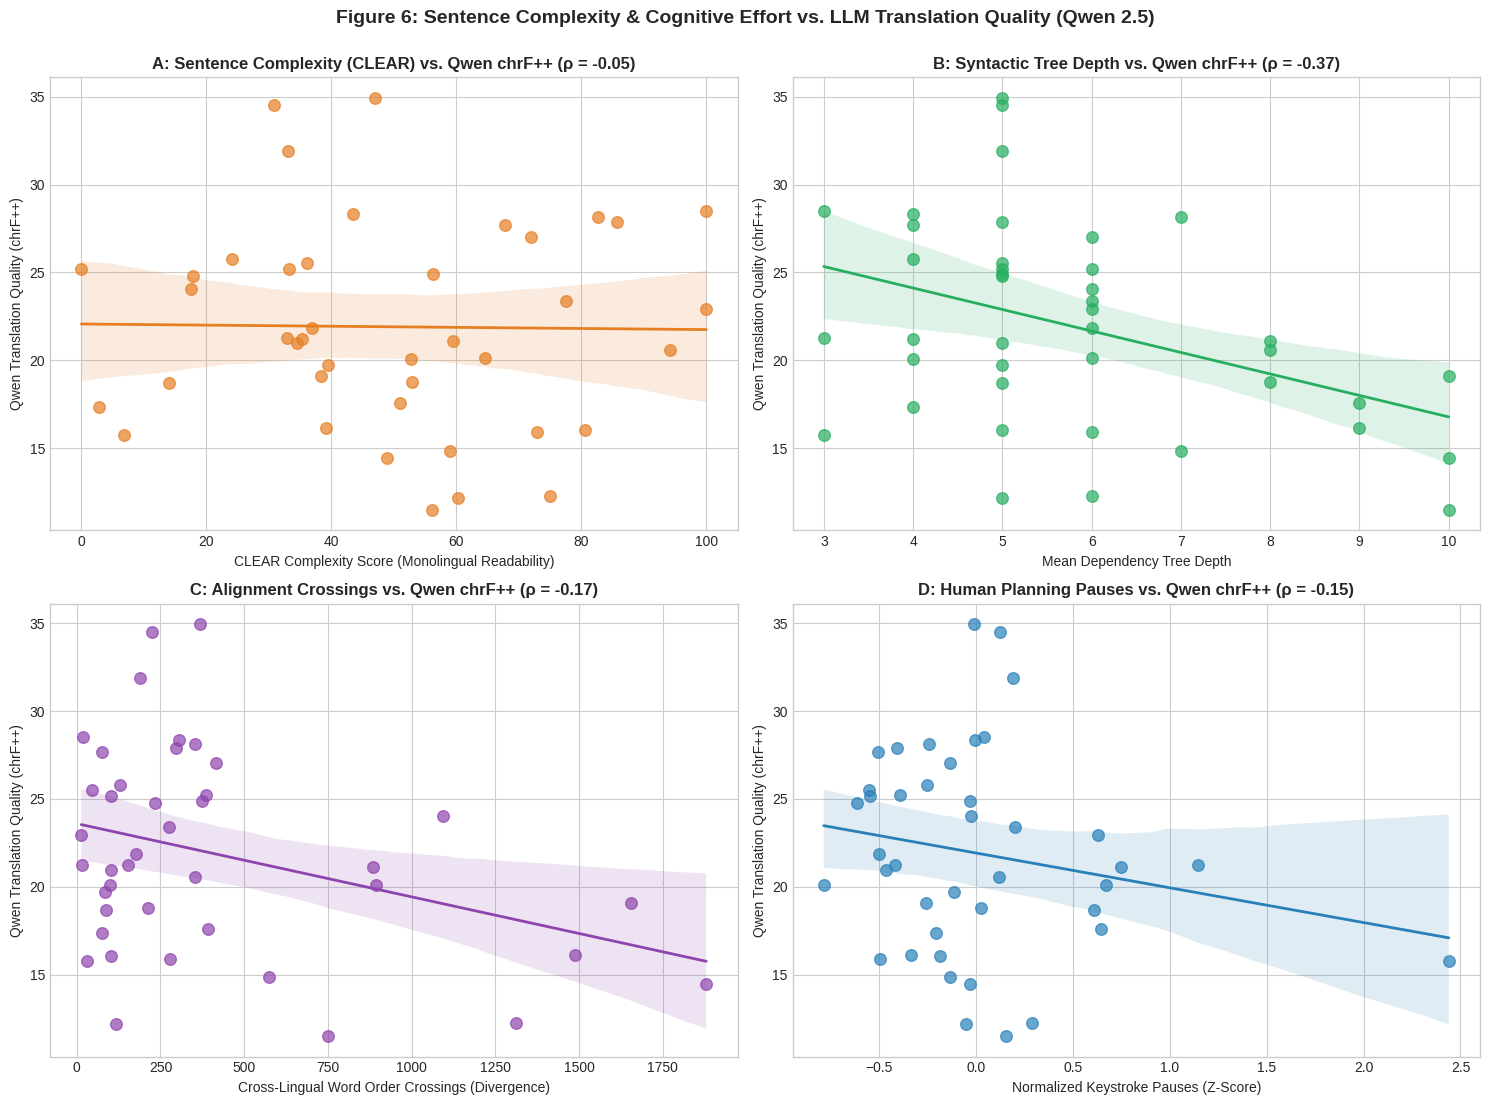

Figure 6 saved -> figures/fig6_complexity_and_cognition_vs_llm_quality.png


In [ ]:
from scipy.stats import spearmanr, pearsonr
import matplotlib.pyplot as plt
import seaborn as sns

eval_df = sent_df.dropna(subset=['qwen_chrf', 'CLEAR_complexity_score']).copy()

corr_metrics = [
    ('CLEAR Complexity Score', 'CLEAR_complexity_score'),
    ('Syntactic Tree Depth', 'mean_tree_depth'),
    ('Alignment Crossings', 'crossings'),
    ('Human Planning Pauses (Z)', 'z_pauses_per_word'),
    ('Human Source Gaze (Z)', 'z_src_gaze_per_word')
]

print('--- Spearman Correlations with Qwen Translation Quality (chrF++) ---')
for label, col in corr_metrics:
    r, p = spearmanr(eval_df[col], eval_df['qwen_chrf'])
    star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    print(f"{label:<28}: ρ = {r:+.3f} (p = {p:.4f}) {star}")

# fig 6: Sentence Complexity & Cognitive Load vs. LLM Quality
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Sentence Complexity (CLEAR) vs Qwen chrF++
r1, p1 = spearmanr(eval_df['CLEAR_complexity_score'], eval_df['qwen_chrf'])
sns.regplot(data=eval_df, x='CLEAR_complexity_score', y='qwen_chrf', ax=axes[0, 0],
            color='#e67e22', scatter_kws={'alpha': 0.7, 's': 70}, line_kws={'lw': 2})
axes[0, 0].set_title(f'A: Sentence Complexity (CLEAR) vs. Qwen chrF++ (ρ = {r1:+.2f})', weight='bold', fontsize=12)
axes[0, 0].set_xlabel('CLEAR Complexity Score (Monolingual Readability)')
axes[0, 0].set_ylabel('Qwen Translation Quality (chrF++)')

# 2. Syntactic Depth vs Qwen chrF++
r2, p2 = spearmanr(eval_df['mean_tree_depth'], eval_df['qwen_chrf'])
sns.regplot(data=eval_df, x='mean_tree_depth', y='qwen_chrf', ax=axes[0, 1],
            color='#27ae60', scatter_kws={'alpha': 0.7, 's': 70}, line_kws={'lw': 2})
axes[0, 1].set_title(f'B: Syntactic Tree Depth vs. Qwen chrF++ (ρ = {r2:+.2f})', weight='bold', fontsize=12)
axes[0, 1].set_xlabel('Mean Dependency Tree Depth')
axes[0, 1].set_ylabel('Qwen Translation Quality (chrF++)')

# 3. English-Hindi Crossings vs Qwen chrF++
r3, p3 = spearmanr(eval_df['crossings'], eval_df['qwen_chrf'])
sns.regplot(data=eval_df, x='crossings', y='qwen_chrf', ax=axes[1, 0],
            color='#8e44ad', scatter_kws={'alpha': 0.7, 's': 70}, line_kws={'lw': 2})
axes[1, 0].set_title(f'C: Alignment Crossings vs. Qwen chrF++ (ρ = {r3:+.2f})', weight='bold', fontsize=12)
axes[1, 0].set_xlabel('Cross-Lingual Word Order Crossings (Divergence)')
axes[1, 0].set_ylabel('Qwen Translation Quality (chrF++)')

# 4. Human Planning Pauses vs Qwen chrF++
r4, p4 = spearmanr(eval_df['z_pauses_per_word'], eval_df['qwen_chrf'])
sns.regplot(data=eval_df, x='z_pauses_per_word', y='qwen_chrf', ax=axes[1, 1],
            color='#2980b9', scatter_kws={'alpha': 0.7, 's': 70}, line_kws={'lw': 2})
axes[1, 1].set_title(f'D: Human Planning Pauses vs. Qwen chrF++ (ρ = {r4:+.2f})', weight='bold', fontsize=12)
axes[1, 1].set_xlabel('Normalized Keystroke Pauses (Z-Score)')
axes[1, 1].set_ylabel('Qwen Translation Quality (chrF++)')

plt.suptitle('Figure 6: Sentence Complexity & Cognitive Effort vs. LLM Translation Quality (Qwen 2.5)', fontsize=14, weight='bold', y=1.00)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig6_complexity_and_cognition_vs_llm_quality.png'), dpi=200)
plt.show()

print('Figure 6 saved -> figures/fig6_complexity_and_cognition_vs_llm_quality.png')
